# Meal Memory: Data Exploration and Baseline

Goal: recognize food photos so users can organize saved meals and
attach related recipes.

AI attribution: Initial notebook code and explanations were drafted
with assistance from OpenAI ChatGPT. Modifications, debugging, and
verification will be documented in ATTRIBUTION.md.

In [2]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
import sys
from pathlib import Path

import torch
import torchvision

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PROJECT_ROOT = Path("/home/users/al581/meal-memory")
assert (PROJECT_ROOT / ".git").is_dir(), "Project folder not found."

print("Project:", PROJECT_ROOT)

Python: /usr/pkg/miniconda-23.9.0/bin/python
PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132
GPU available: True
GPU: NVIDIA GeForce RTX 2080 Ti
Project: /home/users/al581/meal-memory


In [3]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
from torchvision.datasets import Food101

DATA_ROOT = PROJECT_ROOT / "data" / "raw"
DATA_ROOT.mkdir(parents=True, exist_ok=True)

official_train = Food101(
    root=DATA_ROOT,
    split="train",
    download=True,
)

official_test = Food101(
    root=DATA_ROOT,
    split="test",
    download=True,
)

print("Training images:", len(official_train))
print("Test images:", len(official_test))
print("Food categories:", len(official_train.classes))
print("Categories:", official_train.classes)

100%|██████████| 5.00G/5.00G [38:00<00:00, 2.19MB/s]  


Training images: 75750
Test images: 25250
Food categories: 101
Categories: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheese_plate', 'cheesecake', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_and_sour_soup', 'hot_dog', 'huevos_rancheros', 'hummus', 'ice_cream', 'lasagna', 'lobster_bis

In [4]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
import json
import numpy as np
import pandas as pd

SEED = 386

SELECTED_CLASSES = sorted([
    "apple_pie",
    "caesar_salad",
    "cheesecake",
    "chocolate_cake",
    "french_toast",
    "fried_rice",
    "grilled_cheese_sandwich",
    "hamburger",
    "lasagna",
    "macaroni_and_cheese",
    "omelette",
    "pancakes",
    "pizza",
    "ramen",
    "risotto",
    "spaghetti_bolognese",
    "spaghetti_carbonara",
    "sushi",
    "tacos",
    "waffles",
])

assert set(SELECTED_CLASSES).issubset(official_train.classes)

# Our model needs consecutive labels from 0 through 19.
class_to_idx = {
    name: index for index, name in enumerate(SELECTED_CLASSES)
}

# Read the official metadata rather than loading every image.
metadata_dir = DATA_ROOT / "food-101" / "meta"

with open(metadata_dir / "train.json") as file:
    train_metadata = json.load(file)

with open(metadata_dir / "test.json") as file:
    test_metadata = json.load(file)

rng = np.random.default_rng(SEED)
rows = []

for class_name in SELECTED_CLASSES:
    train_ids = np.array(sorted(train_metadata[class_name]))
    rng.shuffle(train_ids)

    partitions = {
        "train": train_ids[:600],
        "validation": train_ids[600:675],
        "calibration": train_ids[675:],
        "test": sorted(test_metadata[class_name]),
    }

    for split_name, image_ids in partitions.items():
        for image_id in image_ids:
            rows.append({
                "image_id": str(image_id),
                "relative_path": f"images/{image_id}.jpg",
                "class_name": class_name,
                "label": class_to_idx[class_name],
                "split": split_name,
            })

manifest = pd.DataFrame(rows)

# Verify that each image appears exactly once.
assert not manifest["image_id"].duplicated().any()

expected_counts = {
    "train": 600,
    "validation": 75,
    "calibration": 75,
    "test": 250,
}

counts = pd.crosstab(manifest["class_name"], manifest["split"])

for split_name, expected in expected_counts.items():
    assert (counts[split_name] == expected).all()

print("Images per split:")
print(manifest["split"].value_counts())
print("\nImages per class:")
display(counts)

Images per split:
split
train          12000
test            5000
validation      1500
calibration     1500
Name: count, dtype: int64

Images per class:


split,calibration,test,train,validation
class_name,,,,
apple_pie,75,250,600,75
caesar_salad,75,250,600,75
cheesecake,75,250,600,75
chocolate_cake,75,250,600,75
french_toast,75,250,600,75
fried_rice,75,250,600,75
grilled_cheese_sandwich,75,250,600,75
hamburger,75,250,600,75
lasagna,75,250,600,75


In [5]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

manifest.to_csv(SPLIT_DIR / "food20_manifest.csv", index=False)

with open(SPLIT_DIR / "food20_config.json", "w") as file:
    json.dump(
        {
            "seed": SEED,
            "classes": SELECTED_CLASSES,
            "class_to_idx": class_to_idx,
            "images_per_class": expected_counts,
        },
        file,
        indent=2,
    )

print("Saved split manifest and class mapping to:", SPLIT_DIR)

Saved split manifest and class mapping to: /home/users/al581/meal-memory/data/splits


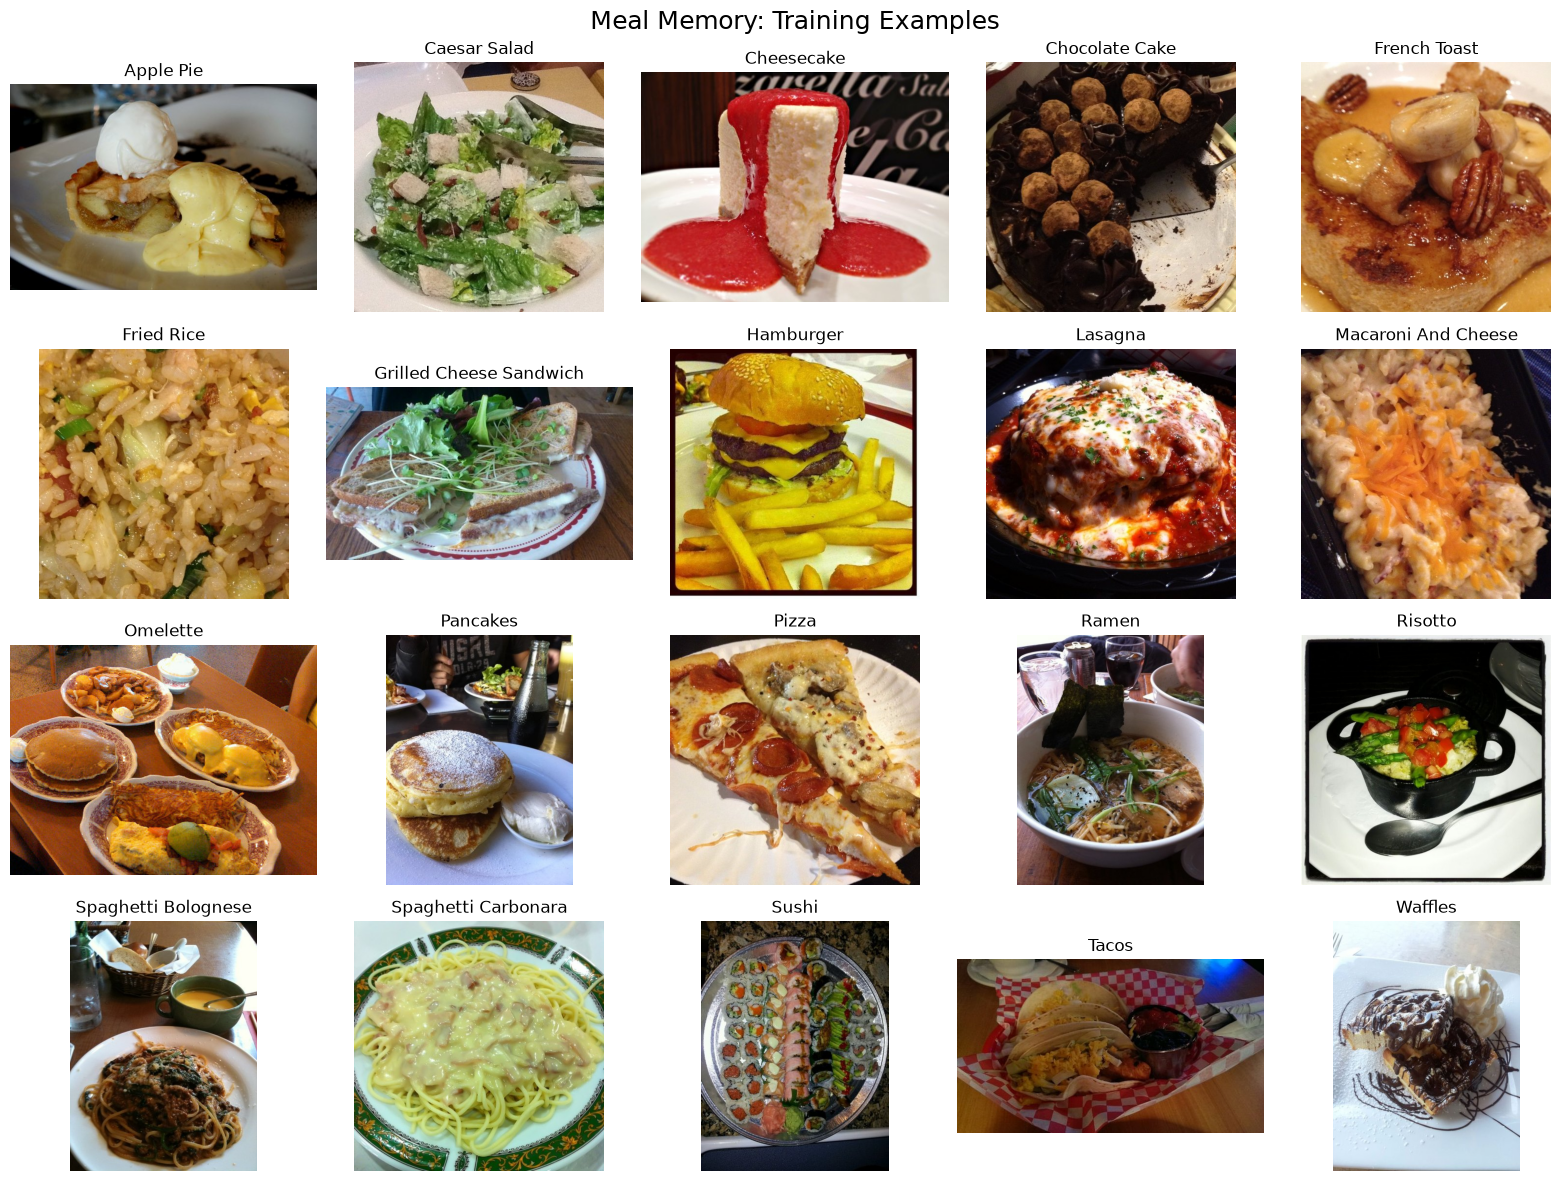

In [6]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
import matplotlib.pyplot as plt
from PIL import Image

IMAGE_ROOT = DATA_ROOT / "food-101"

training_rows = manifest[manifest["split"] == "train"]

fig, axes = plt.subplots(4, 5, figsize=(16, 12))

for ax, class_name in zip(axes.flat, SELECTED_CLASSES):
    row = training_rows[
        training_rows["class_name"] == class_name
    ].sample(n=1, random_state=SEED).iloc[0]

    image_path = IMAGE_ROOT / row["relative_path"]

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(class_name.replace("_", " ").title())
    ax.axis("off")

plt.suptitle("Meal Memory: Training Examples", fontsize=18)
plt.tight_layout()
plt.show()

## Pretrained EfficientNet Baseline

We use ImageNet-pretrained EfficientNet-B0 with a new 20-class output
layer. Initially, the backbone will remain frozen.

For the initial baseline, we use the pretrained weights' standard
preprocessing. Data augmentation will be evaluated separately.

In [7]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
import random
from torch.utils.data import Dataset, DataLoader
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights,
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weights = EfficientNet_B0_Weights.DEFAULT
preprocess = weights.transforms()


class MealDataset(Dataset):
    """Load manifest-selected food images.

    AI attribution: Drafted with assistance from OpenAI ChatGPT.
    """

    def __init__(self, rows, image_root, transform):
        self.rows = rows.reset_index(drop=True).copy()
        self.image_root = image_root
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]

        with Image.open(self.image_root / row["relative_path"]) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        return image, int(row["label"])


train_dataset = MealDataset(
    manifest[manifest["split"] == "train"],
    IMAGE_ROOT,
    preprocess,
)

val_dataset = MealDataset(
    manifest[manifest["split"] == "validation"],
    IMAGE_ROOT,
    preprocess,
)

# Start with zero workers for reliable notebook execution.
loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
    generator=loader_generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

print("Device:", device)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Device: cuda
Training images: 12000
Validation images: 1500
Training batches: 375
Validation batches: 47


In [8]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
from torch import nn

model = efficientnet_b0(weights=weights)

# Freeze the existing pretrained parameters.
for parameter in model.parameters():
    parameter.requires_grad = False

# The new layer is trainable by default.
input_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(
    input_features,
    len(SELECTED_CLASSES),
)

model = model.to(device)

total_parameters = sum(p.numel() for p in model.parameters())
trainable_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")

# Check that a batch passes through the model.
images, labels = next(iter(train_loader))

model.eval()
with torch.no_grad():
    outputs = model(images.to(device))

assert outputs.shape == (len(labels), len(SELECTED_CLASSES))
assert torch.isfinite(outputs).all()
assert labels.min() >= 0
assert labels.max() < len(SELECTED_CLASSES)

print("Image batch shape:", tuple(images.shape))
print("Output shape:", tuple(outputs.shape))
print("Forward pass successful.")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /home/users/al581/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 22.2MB/s]


Total parameters: 4,033,168
Trainable parameters: 25,620
Image batch shape: (32, 3, 224, 224)
Output shape: (32, 20)
Forward pass successful.


## Train the Frozen-Backbone Baseline

Train only the new classifier using cross-entropy loss and Adam.
Keep the pretrained backbone in evaluation mode so its batch-normalization
statistics remain fixed. Enable dropout in the classifier during training.

Select the best checkpoint using validation loss, with early stopping
after two consecutive epochs without improvement.

In [9]:
# AI attribution: Training code drafted with assistance from OpenAI ChatGPT.
import time

RUN_DIR = PROJECT_ROOT / "checkpoints" / "efficientnet_frozen_v1"
RESULTS_DIR = PROJECT_ROOT / "docs" / "results"
RUN_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Prevent accidentally overwriting a previous experiment.
if (RUN_DIR / "last.pt").exists():
    raise RuntimeError(
        "This run already has a checkpoint. Stop here so we can resume "
        "it or choose a different run name."
    )

config = {
    "model": "efficientnet_b0",
    "weights": str(weights),
    "backbone": "frozen",
    "augmentation": False,
    "learning_rate": 1e-3,
    "batch_size": 32,
    "max_epochs": 5,
    "patience": 2,
    "seed": SEED,
}

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad],
    lr=config["learning_rate"],
)

history = []
best_val_loss = float("inf")
epochs_without_improvement = 0


def run_epoch(model, loader, optimizer=None):
    """Run one training or validation epoch.

    AI attribution: Drafted with assistance from OpenAI ChatGPT.
    """
    training = optimizer is not None

    # Freeze backbone behavior, including batch-normalization statistics.
    model.eval()
    if training:
        model.classifier.train()

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    with torch.set_grad_enabled(training):
        for batch_index, (images, labels) in enumerate(loader, start=1):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss encountered.")

            if training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_images += batch_size
            total_loss += loss.item() * batch_size
            total_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()

            if training and batch_index % 100 == 0:
                print(
                    f"  Batch {batch_index}/{len(loader)} "
                    f"| loss {total_loss / total_images:.4f} "
                    f"| accuracy {total_correct / total_images:.1%}",
                    flush=True,
                )

    return (
        total_loss / total_images,
        total_correct / total_images,
    )


for epoch in range(1, config["max_epochs"] + 1):
    start_time = time.perf_counter()
    print(f"\nEpoch {epoch}/{config['max_epochs']}", flush=True)

    train_loss, train_accuracy = run_epoch(
        model, train_loader, optimizer
    )
    val_loss, val_accuracy = run_epoch(model, val_loader)

    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "seconds": time.perf_counter() - start_time,
    })

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "classes": SELECTED_CLASSES,
        "class_to_idx": class_to_idx,
        "config": config,
        "history": history,
        "best_val_loss": best_val_loss,
        "epochs_without_improvement": epochs_without_improvement,
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_states": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available() else []
        ),
        "loader_rng_state": loader_generator.get_state(),
    }

    torch.save(checkpoint, RUN_DIR / "last.pt")
    if improved:
        torch.save(checkpoint, RUN_DIR / "best.pt")

    pd.DataFrame(history).to_csv(
        RESULTS_DIR / "efficientnet_frozen_v1_history.csv",
        index=False,
    )

    print(
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.1%}\n"
        f"Val loss:   {val_loss:.4f} | "
        f"Val accuracy:   {val_accuracy:.1%}\n"
        f"Epoch time: {history[-1]['seconds']:.1f} seconds"
        + (" | Saved new best model" if improved else ""),
        flush=True,
    )

    if epochs_without_improvement >= config["patience"]:
        print("Early stopping: validation loss stopped improving.")
        break

print("\nBaseline run finished. Best checkpoint:", RUN_DIR / "best.pt")


Epoch 1/5
  Batch 100/375 | loss 1.7463 | accuracy 58.1%
  Batch 200/375 | loss 1.3845 | accuracy 65.7%
  Batch 300/375 | loss 1.2208 | accuracy 68.9%
Train loss: 1.1402 | Train accuracy: 70.2%
Val loss:   0.8014 | Val accuracy:   76.9%
Epoch time: 280.6 seconds | Saved new best model

Epoch 2/5
  Batch 100/375 | loss 0.7239 | accuracy 79.0%
  Batch 200/375 | loss 0.7123 | accuracy 79.0%
  Batch 300/375 | loss 0.6991 | accuracy 79.3%
Train loss: 0.6953 | Train accuracy: 79.5%
Val loss:   0.7153 | Val accuracy:   78.3%
Epoch time: 87.5 seconds | Saved new best model

Epoch 3/5
  Batch 100/375 | loss 0.6332 | accuracy 81.6%
  Batch 200/375 | loss 0.6144 | accuracy 82.2%
  Batch 300/375 | loss 0.6020 | accuracy 82.2%
Train loss: 0.5978 | Train accuracy: 82.2%
Val loss:   0.6898 | Val accuracy:   79.1%
Epoch time: 87.7 seconds | Saved new best model

Epoch 4/5
  Batch 100/375 | loss 0.5152 | accuracy 84.9%
  Batch 200/375 | loss 0.5327 | accuracy 84.2%
  Batch 300/375 | loss 0.5395 | accu

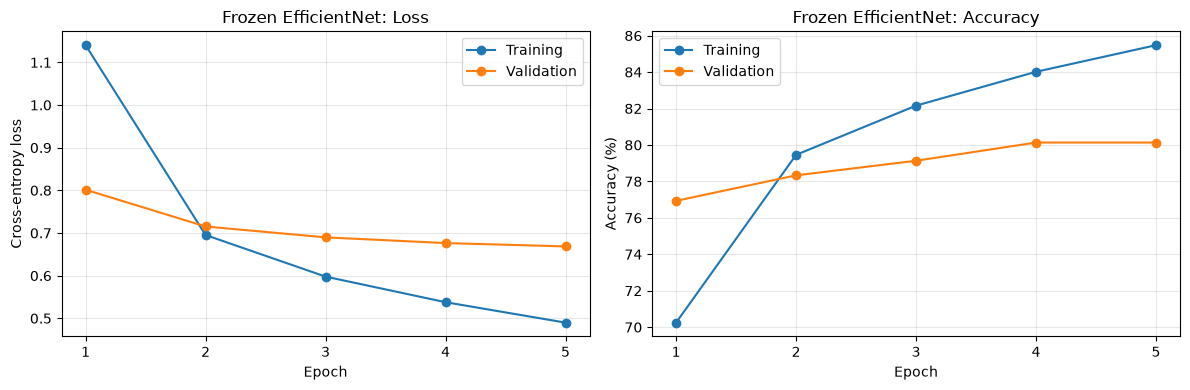

In [10]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
history_df = pd.read_csv(
    RESULTS_DIR / "efficientnet_frozen_v1_history.csv"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_df["epoch"], history_df["train_loss"],
    marker="o", label="Training",
)
axes[0].plot(
    history_df["epoch"], history_df["val_loss"],
    marker="o", label="Validation",
)
axes[0].set_title("Frozen EfficientNet: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(
    history_df["epoch"], history_df["train_accuracy"] * 100,
    marker="o", label="Training",
)
axes[1].plot(
    history_df["epoch"], history_df["val_accuracy"] * 100,
    marker="o", label="Validation",
)
axes[1].set_title("Frozen EfficientNet: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()

for ax in axes:
    ax.set_xticks(history_df["epoch"])
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "efficientnet_frozen_v1_curves.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

## Fine-Tuning EfficientNet

Initialize from the best frozen-backbone checkpoint and unfreeze
the last two feature blocks. Use a smaller learning rate for the
pretrained layers than for the classifier.

Keep batch-normalization statistics fixed, matching the baseline.
Use the same preprocessing and data splits for this first comparison.

In [11]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
BASELINE_PATH = (
    PROJECT_ROOT
    / "checkpoints"
    / "efficientnet_frozen_v1"
    / "best.pt"
)

baseline_checkpoint = torch.load(
    BASELINE_PATH,
    map_location="cpu",
    weights_only=True,
)

assert baseline_checkpoint["classes"] == SELECTED_CLASSES
assert baseline_checkpoint["class_to_idx"] == class_to_idx

# Create a separate model; checkpoint supplies the learned weights.
ft_model = efficientnet_b0(weights=None)
input_features = ft_model.classifier[1].in_features
ft_model.classifier[1] = nn.Linear(
    input_features, len(SELECTED_CLASSES)
)
ft_model.load_state_dict(baseline_checkpoint["model_state_dict"])

# Freeze everything first.
for parameter in ft_model.parameters():
    parameter.requires_grad = False

# Unfreeze the last two feature blocks and classifier.
for block in ft_model.features[-2:]:
    for parameter in block.parameters():
        parameter.requires_grad = True

for parameter in ft_model.classifier.parameters():
    parameter.requires_grad = True

ft_model = ft_model.to(device)

ft_optimizer = torch.optim.Adam([
    {
        "params": [
            p for p in ft_model.features.parameters()
            if p.requires_grad
        ],
        "lr": 1e-5,
    },
    {
        "params": ft_model.classifier.parameters(),
        "lr": 1e-4,
    },
])

print("Loaded baseline epoch:", baseline_checkpoint["epoch"])
print(
    "Baseline validation accuracy:",
    f"{baseline_checkpoint['history'][-1]['val_accuracy']:.1%}",
)
print(
    "Fine-tuning trainable parameters:",
    f"{sum(p.numel() for p in ft_model.parameters() if p.requires_grad):,}",
)
print("Backbone learning rate:", ft_optimizer.param_groups[0]["lr"])
print("Classifier learning rate:", ft_optimizer.param_groups[1]["lr"])

# Verify that loading the checkpoint reproduces validation performance.
ft_val_loss, ft_val_accuracy = run_epoch(ft_model, val_loader)

print(f"\nBefore fine-tuning — validation loss: {ft_val_loss:.4f}")
print(f"Before fine-tuning — validation accuracy: {ft_val_accuracy:.1%}")

Loaded baseline epoch: 5
Baseline validation accuracy: 80.1%
Fine-tuning trainable parameters: 1,155,012
Backbone learning rate: 1e-05
Classifier learning rate: 0.0001

Before fine-tuning — validation loss: 0.6686
Before fine-tuning — validation accuracy: 80.1%


In [12]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
FT_RUN_DIR = (
    PROJECT_ROOT / "checkpoints" / "efficientnet_finetuned_v1"
)
FT_RUN_DIR.mkdir(parents=True, exist_ok=True)

if any(FT_RUN_DIR.glob("*.pt")):
    raise RuntimeError(
        "Fine-tuning checkpoints already exist. Stop here so we can "
        "resume the run or choose a new run name."
    )

ft_config = {
    "model": "efficientnet_b0",
    "initial_checkpoint": str(BASELINE_PATH.relative_to(PROJECT_ROOT)),
    "backbone": "last_two_feature_blocks_unfrozen",
    "batch_norm": "fixed_running_statistics",
    "augmentation": False,
    "loss": "cross_entropy",
    "backbone_learning_rate": 1e-5,
    "classifier_learning_rate": 1e-4,
    "batch_size": train_loader.batch_size,
    "max_epochs": 5,
    "patience": 2,
    "seed": SEED,
}

# Reset randomness so this experiment has a documented starting state.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
loader_generator.manual_seed(SEED)

ft_history = []

# Keep the baseline if fine-tuning never improves validation loss.
ft_best_val_loss = ft_val_loss
ft_epochs_without_improvement = 0


def save_ft_checkpoint(path, epoch):
    """Save fine-tuning state.

    AI attribution: Drafted with assistance from OpenAI ChatGPT.
    """
    torch.save({
        "epoch": epoch,
        "model_state_dict": ft_model.state_dict(),
        "optimizer_state_dict": ft_optimizer.state_dict(),
        "classes": SELECTED_CLASSES,
        "class_to_idx": class_to_idx,
        "config": ft_config,
        "history": list(ft_history),
        "best_val_loss": ft_best_val_loss,
        "epochs_without_improvement": ft_epochs_without_improvement,
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_states": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available() else []
        ),
        "loader_rng_state": loader_generator.get_state(),
    }, path)


# Epoch 0 means the starting baseline, before fine-tuning.
save_ft_checkpoint(FT_RUN_DIR / "best.pt", epoch=0)

for epoch in range(1, ft_config["max_epochs"] + 1):
    start_time = time.perf_counter()
    print(
        f"\nFine-tuning epoch {epoch}/{ft_config['max_epochs']}",
        flush=True,
    )

    train_loss, train_accuracy = run_epoch(
        ft_model, train_loader, ft_optimizer
    )
    val_loss, val_accuracy = run_epoch(ft_model, val_loader)

    improved = val_loss < ft_best_val_loss

    if improved:
        ft_best_val_loss = val_loss
        ft_epochs_without_improvement = 0
    else:
        ft_epochs_without_improvement += 1

    ft_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "seconds": time.perf_counter() - start_time,
    })

    save_ft_checkpoint(FT_RUN_DIR / "last.pt", epoch)
    if improved:
        save_ft_checkpoint(FT_RUN_DIR / "best.pt", epoch)

    pd.DataFrame(ft_history).to_csv(
        RESULTS_DIR / "efficientnet_finetuned_v1_history.csv",
        index=False,
    )

    print(
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.1%}\n"
        f"Val loss:   {val_loss:.4f} | "
        f"Val accuracy:   {val_accuracy:.1%}\n"
        f"Epoch time: {ft_history[-1]['seconds']:.1f} seconds"
        + (" | Saved new best model" if improved else ""),
        flush=True,
    )

    if ft_epochs_without_improvement >= ft_config["patience"]:
        print("Early stopping: validation loss stopped improving.")
        break

print("\nRun finished. Best checkpoint:", FT_RUN_DIR / "best.pt")


Fine-tuning epoch 1/5
  Batch 100/375 | loss 0.4119 | accuracy 87.5%
  Batch 200/375 | loss 0.4165 | accuracy 87.4%
  Batch 300/375 | loss 0.4159 | accuracy 87.1%
Train loss: 0.4221 | Train accuracy: 86.9%
Val loss:   0.6501 | Val accuracy:   80.5%
Epoch time: 89.3 seconds | Saved new best model

Fine-tuning epoch 2/5
  Batch 100/375 | loss 0.3701 | accuracy 88.4%
  Batch 200/375 | loss 0.3895 | accuracy 88.2%
  Batch 300/375 | loss 0.3967 | accuracy 87.9%
Train loss: 0.3970 | Train accuracy: 87.9%
Val loss:   0.6463 | Val accuracy:   80.7%
Epoch time: 89.5 seconds | Saved new best model

Fine-tuning epoch 3/5
  Batch 100/375 | loss 0.3728 | accuracy 89.1%
  Batch 200/375 | loss 0.3830 | accuracy 88.3%
  Batch 300/375 | loss 0.3748 | accuracy 88.7%
Train loss: 0.3711 | Train accuracy: 88.7%
Val loss:   0.6388 | Val accuracy:   81.2%
Epoch time: 89.6 seconds | Saved new best model

Fine-tuning epoch 4/5
  Batch 100/375 | loss 0.3624 | accuracy 89.5%
  Batch 200/375 | loss 0.3552 | accu

,model,selected_epoch,train_accuracy,val_accuracy,val_loss
0,Frozen backbone,5,0.854750,0.801333,0.668552
1,Fine-tuned last two blocks,5,0.899167,0.816000,0.638603


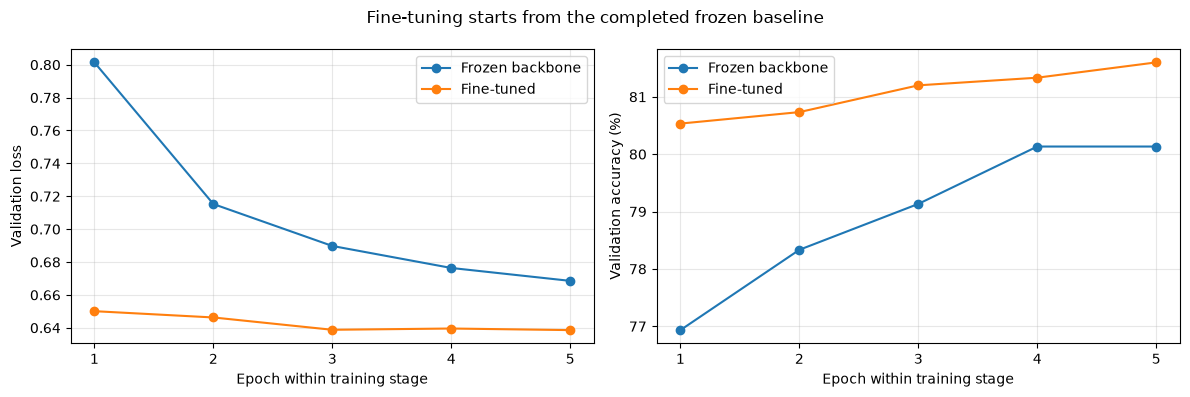

In [13]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
baseline_history = pd.read_csv(
    RESULTS_DIR / "efficientnet_frozen_v1_history.csv"
)
finetuned_history = pd.read_csv(
    RESULTS_DIR / "efficientnet_finetuned_v1_history.csv"
)

comparison_rows = []

for name, run_history in [
    ("Frozen backbone", baseline_history),
    ("Fine-tuned last two blocks", finetuned_history),
]:
    best = run_history.loc[run_history["val_loss"].idxmin()]

    comparison_rows.append({
        "model": name,
        "selected_epoch": int(best["epoch"]),
        "train_accuracy": best["train_accuracy"],
        "val_accuracy": best["val_accuracy"],
        "val_loss": best["val_loss"],
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(
    RESULTS_DIR / "baseline_vs_finetuned.csv",
    index=False,
)
display(comparison_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, run_history in [
    ("Frozen backbone", baseline_history),
    ("Fine-tuned", finetuned_history),
]:
    axes[0].plot(
        run_history["epoch"], run_history["val_loss"],
        marker="o", label=name,
    )
    axes[1].plot(
        run_history["epoch"], run_history["val_accuracy"] * 100,
        marker="o", label=name,
    )

axes[0].set_ylabel("Validation loss")
axes[1].set_ylabel("Validation accuracy (%)")

for ax in axes:
    ax.set_xlabel("Epoch within training stage")
    ax.set_xticks(range(1, 6))
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle(
    "Fine-tuning starts from the completed frozen baseline"
)
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "baseline_vs_finetuned.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [14]:
%%writefile /home/users/al581/meal-memory/src/training.py
"""Reusable training utilities for Meal Memory.

AI attribution: Drafted with assistance from OpenAI ChatGPT.
"""

import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch


def run_epoch(model, loader, criterion, device, optimizer=None):
    """Run an epoch while keeping backbone running statistics fixed."""
    training = optimizer is not None
    model.eval()

    if training:
        model.classifier.train()

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss encountered.")

            if training:
                loss.backward()
                optimizer.step()

            count = labels.size(0)
            total_images += count
            total_loss += loss.item() * count
            total_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()

    return {
        "loss": total_loss / total_images,
        "accuracy": total_correct / total_images,
    }


def train_experiment(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    device,
    run_dir,
    results_path,
    classes,
    config,
):
    """Train a fresh experiment, preserving its best and latest states."""
    run_dir = Path(run_dir)
    results_path = Path(results_path)

    if any(run_dir.glob("*.pt")) or results_path.exists():
        raise FileExistsError(
            "Experiment outputs already exist; use a new run name "
            "or explicitly resume the existing experiment."
        )

    run_dir.mkdir(parents=True, exist_ok=True)
    results_path.parent.mkdir(parents=True, exist_ok=True)

    seed = config["seed"]
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    if train_loader.generator is not None:
        train_loader.generator.manual_seed(seed)

    initial = run_epoch(model, val_loader, criterion, device)
    best_loss = initial["loss"]
    best_epoch = 0
    stale_epochs = 0
    history = []

    def save_checkpoint(path, epoch):
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "classes": list(classes),
            "class_to_idx": {
                name: index for index, name in enumerate(classes)
            },
            "config": dict(config),
            "history": list(history),
            "initial_validation": initial,
            "best_val_loss": best_loss,
            "best_epoch": best_epoch,
            "epochs_without_improvement": stale_epochs,
            "torch_rng_state": torch.get_rng_state(),
            "cuda_rng_states": (
                torch.cuda.get_rng_state_all()
                if torch.cuda.is_available() else []
            ),
            "loader_rng_state": (
                train_loader.generator.get_state()
                if train_loader.generator is not None else None
            ),
            "python_rng_state": random.getstate(),
        }, path)

    # Preserve the starting checkpoint if training never improves it.
    save_checkpoint(run_dir / "best.pt", epoch=0)

    for epoch in range(1, config["max_epochs"] + 1):
        started = time.perf_counter()
        print(
            f"Epoch {epoch}/{config['max_epochs']} starting...",
            flush=True,
        )

        train = run_epoch(
            model, train_loader, criterion, device, optimizer
        )
        val = run_epoch(model, val_loader, criterion, device)

        improved = val["loss"] < best_loss
        if improved:
            best_loss = val["loss"]
            best_epoch = epoch
            stale_epochs = 0
        else:
            stale_epochs += 1

        history.append({
            "epoch": epoch,
            "train_loss": train["loss"],
            "train_accuracy": train["accuracy"],
            "val_loss": val["loss"],
            "val_accuracy": val["accuracy"],
            "seconds": time.perf_counter() - started,
        })

        save_checkpoint(run_dir / "last.pt", epoch)
        if improved:
            save_checkpoint(run_dir / "best.pt", epoch)

        pd.DataFrame(history).to_csv(results_path, index=False)

        print(
            f"Train loss {train['loss']:.4f} | "
            f"accuracy {train['accuracy']:.1%} | "
            f"Val loss {val['loss']:.4f} | "
            f"accuracy {val['accuracy']:.1%}"
            + (" | New best" if improved else ""),
            flush=True,
        )

        patience = config.get("patience")
        if patience is not None and stale_epochs >= patience:
            print("Early stopping.")
            break

    print(f"Finished. Best validation-loss checkpoint: epoch {best_epoch}")
    return pd.DataFrame(history)

Writing /home/users/al581/meal-memory/src/training.py


In [15]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
import sys
import importlib

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.training as training
importlib.reload(training)

print("Loaded:", training.__file__)
print("Reusable trainer ready.")

Loaded: /home/users/al581/meal-memory/src/training.py
Reusable trainer ready.


## Controlled Comparison: Continue Training the Frozen Backbone

Both this control and the initial fine-tuning experiment start from
the same saved baseline. Both reset the optimizer and use a classifier
learning rate of 1e-4.

This control keeps the backbone frozen for five additional epochs.
The fine-tuning experiment updates its last two feature blocks.

All other data and preprocessing choices remain unchanged.

In [16]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
control_checkpoint = torch.load(
    BASELINE_PATH,
    map_location="cpu",
    weights_only=True,
)

assert control_checkpoint["classes"] == SELECTED_CLASSES
assert control_checkpoint["class_to_idx"] == class_to_idx

control_model = efficientnet_b0(weights=None)
control_model.classifier[1] = nn.Linear(
    control_model.classifier[1].in_features,
    len(SELECTED_CLASSES),
)
control_model.load_state_dict(
    control_checkpoint["model_state_dict"]
)

# Only the classifier is trainable.
for parameter in control_model.parameters():
    parameter.requires_grad = False

for parameter in control_model.classifier.parameters():
    parameter.requires_grad = True

control_model = control_model.to(device)

control_optimizer = torch.optim.Adam(
    control_model.classifier.parameters(),
    lr=1e-4,
)

control_config = {
    "model": "efficientnet_b0",
    "initial_checkpoint": str(
        BASELINE_PATH.relative_to(PROJECT_ROOT)
    ),
    "backbone": "frozen",
    "batch_norm": "fixed_running_statistics",
    "augmentation": False,
    "loss": "cross_entropy",
    "classifier_learning_rate": 1e-4,
    "batch_size": train_loader.batch_size,
    "max_epochs": 5,
    "patience": None,  # Complete the full matched training budget.
    "seed": SEED,
}

print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in control_model.parameters() if p.requires_grad):,}",
)

control_history = training.train_experiment(
    model=control_model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=control_optimizer,
    criterion=nn.CrossEntropyLoss(),
    device=device,
    run_dir=(
        PROJECT_ROOT / "checkpoints" / "efficientnet_frozen_control_v1"
    ),
    results_path=(
        RESULTS_DIR / "efficientnet_frozen_control_v1_history.csv"
    ),
    classes=SELECTED_CLASSES,
    config=control_config,
)

Trainable parameters: 25,620
Epoch 1/5 starting...
Train loss 0.4353 | accuracy 87.0% | Val loss 0.6580 | accuracy 80.1% | New best
Epoch 2/5 starting...
Train loss 0.4316 | accuracy 87.6% | Val loss 0.6560 | accuracy 80.1% | New best
Epoch 3/5 starting...
Train loss 0.4254 | accuracy 87.8% | Val loss 0.6542 | accuracy 80.3% | New best
Epoch 4/5 starting...
Train loss 0.4188 | accuracy 87.8% | Val loss 0.6539 | accuracy 80.2% | New best
Epoch 5/5 starting...
Train loss 0.4191 | accuracy 88.0% | Val loss 0.6549 | accuracy 80.2%
Finished. Best validation-loss checkpoint: epoch 4


In [17]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
run_files = {
    "Original frozen baseline":
        "efficientnet_frozen_v1_history.csv",
    "Frozen continuation":
        "efficientnet_frozen_control_v1_history.csv",
    "Fine-tuned last two blocks":
        "efficientnet_finetuned_v1_history.csv",
}

comparison_rows = []

for name, filename in run_files.items():
    run_history = pd.read_csv(RESULTS_DIR / filename)
    best = run_history.loc[run_history["val_loss"].idxmin()]

    comparison_rows.append({
        "approach": name,
        "selected_epoch": int(best["epoch"]),
        "val_loss": best["val_loss"],
        "val_accuracy": best["val_accuracy"],
    })

controlled_comparison = pd.DataFrame(comparison_rows)
controlled_comparison.to_csv(
    RESULTS_DIR / "controlled_backbone_comparison.csv",
    index=False,
)
display(controlled_comparison)

,approach,selected_epoch,val_loss,val_accuracy
0,Original frozen baseline,5,0.668552,0.801333
1,Frozen continuation,4,0.653939,0.802000
2,Fine-tuned last two blocks,5,0.638603,0.816000


### Controlled backbone comparison

Starting from the same baseline checkpoint, we compared five additional
epochs of classifier-only training with five epochs updating the last
two feature blocks. Both used the same classifier learning rate, seed,
preprocessing, and data splits.

The best validation-loss checkpoints achieved approximately 80.2%
accuracy for frozen continuation and 81.6% for partial fine-tuning.

This single-seed experiment supports partial fine-tuning for our task.
Calibration and test partitions have not been used.

In [18]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
experiments = [
    ("efficientnet_lr_3e6_v1", 3e-6),
    ("efficientnet_lr_3e5_v1", 3e-5),
]

# Check both destinations before starting any training.
for run_name, _ in experiments:
    destination = PROJECT_ROOT / "checkpoints" / run_name
    results_file = RESULTS_DIR / f"{run_name}_history.csv"

    if any(destination.glob("*.pt")) or results_file.exists():
        raise FileExistsError(
            f"Outputs already exist for {run_name}. "
            "Stop here so we can resume or reuse completed results."
        )

for run_name, backbone_lr in experiments:
    print(f"\n{'=' * 60}")
    print(f"Starting {run_name}: backbone LR = {backbone_lr}")
    print(f"{'=' * 60}", flush=True)

    # Always initialize from the original frozen baseline.
    checkpoint = torch.load(
        BASELINE_PATH,
        map_location="cpu",
        weights_only=True,
    )
    assert checkpoint["classes"] == SELECTED_CLASSES
    assert checkpoint["class_to_idx"] == class_to_idx

    experiment_model = efficientnet_b0(weights=None)
    experiment_model.classifier[1] = nn.Linear(
        experiment_model.classifier[1].in_features,
        len(SELECTED_CLASSES),
    )
    experiment_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    for parameter in experiment_model.parameters():
        parameter.requires_grad = False

    for block in experiment_model.features[-2:]:
        for parameter in block.parameters():
            parameter.requires_grad = True

    for parameter in experiment_model.classifier.parameters():
        parameter.requires_grad = True

    experiment_model = experiment_model.to(device)

    experiment_optimizer = torch.optim.Adam([
        {
            "params": [
                p for p in experiment_model.features.parameters()
                if p.requires_grad
            ],
            "lr": backbone_lr,
        },
        {
            "params": experiment_model.classifier.parameters(),
            "lr": 1e-4,
        },
    ])

    experiment_config = {
        "model": "efficientnet_b0",
        "initial_checkpoint": str(
            BASELINE_PATH.relative_to(PROJECT_ROOT)
        ),
        "backbone": "last_two_feature_blocks_unfrozen",
        "batch_norm": "fixed_running_statistics",
        "augmentation": False,
        "loss": "cross_entropy",
        "backbone_learning_rate": backbone_lr,
        "classifier_learning_rate": 1e-4,
        "batch_size": train_loader.batch_size,
        "max_epochs": 5,
        "patience": None,
        "seed": SEED,
    }

    training.train_experiment(
        model=experiment_model,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=experiment_optimizer,
        criterion=nn.CrossEntropyLoss(),
        device=device,
        run_dir=PROJECT_ROOT / "checkpoints" / run_name,
        results_path=RESULTS_DIR / f"{run_name}_history.csv",
        classes=SELECTED_CLASSES,
        config=experiment_config,
    )

    del experiment_optimizer, experiment_model, checkpoint
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nBoth learning-rate experiments finished.")


Starting efficientnet_lr_3e6_v1: backbone LR = 3e-06
Epoch 1/5 starting...
Train loss 0.4269 | accuracy 86.9% | Val loss 0.6531 | accuracy 80.5% | New best
Epoch 2/5 starting...
Train loss 0.4119 | accuracy 87.6% | Val loss 0.6507 | accuracy 80.5% | New best
Epoch 3/5 starting...
Train loss 0.3963 | accuracy 88.0% | Val loss 0.6468 | accuracy 80.8% | New best
Epoch 4/5 starting...
Train loss 0.3820 | accuracy 88.3% | Val loss 0.6471 | accuracy 80.5%
Epoch 5/5 starting...
Train loss 0.3769 | accuracy 88.4% | Val loss 0.6482 | accuracy 80.7%
Finished. Best validation-loss checkpoint: epoch 3

Starting efficientnet_lr_3e5_v1: backbone LR = 3e-05
Epoch 1/5 starting...
Train loss 0.4210 | accuracy 86.9% | Val loss 0.6404 | accuracy 80.9% | New best
Epoch 2/5 starting...
Train loss 0.3695 | accuracy 88.8% | Val loss 0.6349 | accuracy 81.6% | New best
Epoch 3/5 starting...
Train loss 0.3222 | accuracy 90.6% | Val loss 0.6257 | accuracy 81.9% | New best
Epoch 4/5 starting...
Train loss 0.2820

In [19]:
# AI attribution: Drafted with assistance from OpenAI ChatGPT.
tuning_runs = [
    ("efficientnet_lr_3e6_v1", 3e-6),
    ("efficientnet_finetuned_v1", 1e-5),
    ("efficientnet_lr_3e5_v1", 3e-5),
]

tuning_rows = []

for run_name, backbone_lr in tuning_runs:
    best = torch.load(
        PROJECT_ROOT / "checkpoints" / run_name / "best.pt",
        map_location="cpu",
        weights_only=True,
    )

    selected_epoch = best["epoch"]

    if selected_epoch == 0:
        val_loss = best["initial_validation"]["loss"]
        val_accuracy = best["initial_validation"]["accuracy"]
    else:
        selected_row = next(
            row for row in best["history"]
            if row["epoch"] == selected_epoch
        )
        val_loss = selected_row["val_loss"]
        val_accuracy = selected_row["val_accuracy"]

    tuning_rows.append({
        "run": run_name,
        "backbone_lr": backbone_lr,
        "classifier_lr": 1e-4,
        "selected_epoch": selected_epoch,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values("val_loss")
tuning_results.to_csv(
    RESULTS_DIR / "learning_rate_tuning.csv",
    index=False,
)

display(tuning_results)
print(
    "Selected by lowest validation loss:",
    tuning_results.iloc[0]["run"],
)

,run,backbone_lr,classifier_lr,selected_epoch,val_loss,val_accuracy
2,efficientnet_lr_3e5_v1,0.000030,0.0001,3,0.625740,0.819333
1,efficientnet_finetuned_v1,0.000010,0.0001,5,0.638603,0.816000
0,efficientnet_lr_3e6_v1,0.000003,0.0001,3,0.646800,0.808000


Selected by lowest validation loss: efficientnet_lr_3e5_v1
